In [731]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy
import random
import math

names = open ('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(names))))
stoi= {s:i+1 for i,s in enumerate(chars)} 
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
#print(itos)


In [732]:
n_embd = 10      
block_size = 3   
n_hidden = 300   

def dataset(names):

    
    x, y = [] , []

    for name in names:
        #print(name)
        
        context = [0] * block_size
        for ch in name+ '.':
            ix= stoi[ch]
            x.append(context)
            y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]
            
            
    x = torch.tensor(x)
    y = torch.tensor(y)
    
    return x,y

random.seed(58)
random.shuffle(names)
n1=int(len(names)*0.8)
n2=int(len(names)*0.9)
n3=int(len(names))
xtr, ytr = dataset(names[:n1])
#xdev, ydev = dataset(names[n1:n2])
#xte, yte = dataset(names[n2:])




In [733]:
c = torch.randn((27,n_embd))
c.shape

torch.Size([27, 10])

In [734]:
emb= c[xtr]
emb.shape


torch.Size([182578, 3, 10])

In [735]:
w1 = torch.randn((n_embd * block_size, n_hidden)) * (5/3) / ((n_embd * block_size) ** 0.5)
b1= torch.randn(n_hidden) * 0.01
h = torch.tanh(emb.view(-1, n_embd * block_size) @ w1)
w2= torch.randn((n_hidden,27)) *0.01
b2= torch.randn(27) * 0

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [c,w1,w2,b2,bngain,bnbias]

h.shape

torch.Size([182578, 300])

In [736]:
logits = h @ w2 + b2
prob = logits.exp() / logits.exp().sum(1, keepdim=True) 
loss = -prob[torch.arange(xtr.shape[0]), ytr ].log().mean()

#loss = F.cross_entropy(logits , y)
loss


lre = torch.linspace(-3,0,1000)
lrs = 10**lre
lri , lossi = [],[]
step = []
loss

tensor(3.2965)

In [737]:
loss = F.cross_entropy(logits , ytr)
loss

tensor(3.2965)

In [738]:
"""plt.figure(figsize=(20, 4))
plt.hist(h.view(-1).tolist(), 50)"""
    
"""plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')"""

"plt.figure(figsize=(20, 10))\nplt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')"

      0: 3.3112
  10000: 2.4119
  20000: 2.2865
  30000: 2.2105
  40000: 2.0011
  50000: 2.4361
  60000: 2.0491
  70000: 2.1206
  80000: 2.1303
  90000: 2.2573
 100000: 2.6618
 110000: 2.1516
 120000: 1.9671
 130000: 1.8789
 140000: 2.1754
 150000: 1.9437
 160000: 1.8646
 170000: 1.6985
 180000: 1.8272
 190000: 2.1941


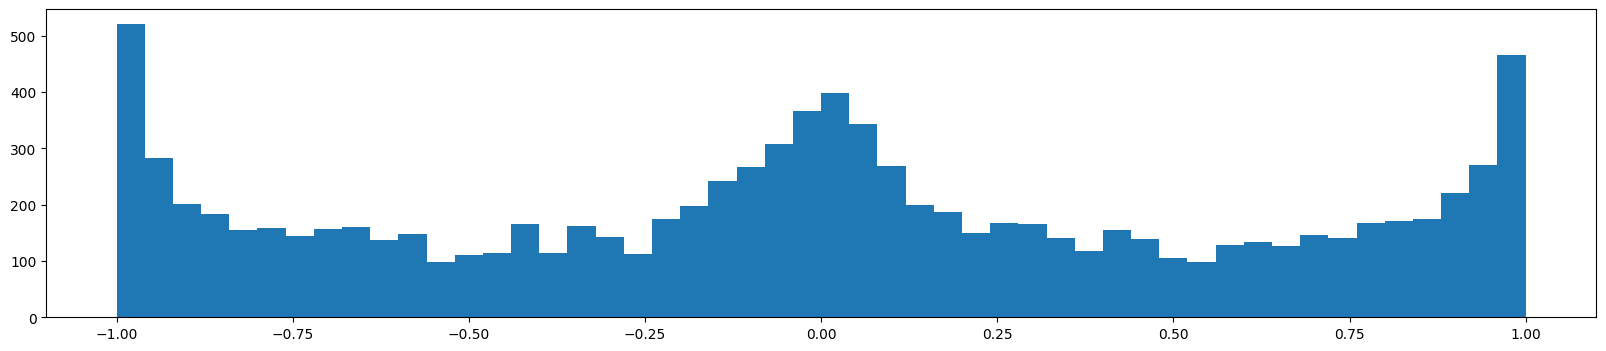

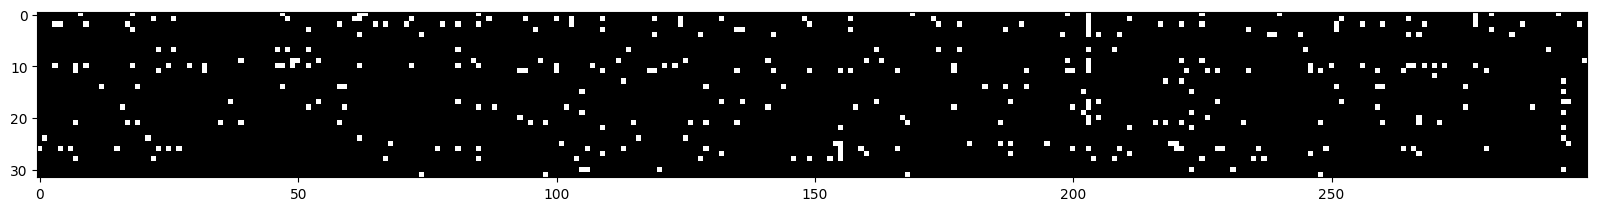

In [739]:
for p in parameters:
    p.requires_grad = True

for i in range(200000):
        
    ix = torch.randint(0, xtr.shape[0],(32,))
    emb= c[xtr[ix]]
    hpreact = (emb.view(-1, n_embd * block_size))@ w1  
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact= bngain * (hpreact - bnmeani) / bnstdi + bnbias
    
    

    h = torch.tanh(hpreact)           #hpreact 
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits , ytr[ix])
    
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
    
    for p in parameters:
        p.grad = None
    
    loss.backward()

    #lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01

    for p in parameters:
        p.data += lr * -p.grad
        
    if i %10000 == 0:
        print(f'{i:7d}: {loss.item():.4f}') 
        
    step.append(i)    
    #lri.append(lre[i])
    lossi.append(loss.log10().item())
    
    
plt.figure(figsize=(20, 4))
plt.hist(h.view(-1).tolist(), 50)
    
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')
    
    
    

#print(loss.item())



In [740]:
#plt.plot(lri,lossi)
#plt.plot(step, lossi)


In [741]:

emb= c[xdev]
hpreact = emb.view(-1, n_embd * block_size) @ w1
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2
loss = F.cross_entropy(logits , ydev)
loss


tensor(2.5044, grad_fn=<NllLossBackward0>)

In [742]:
emb= c[xtr]
hpreact = emb.view(-1, n_embd * block_size) @ w1
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2
loss = F.cross_entropy(logits , ytr)
loss

tensor(2.0497, grad_fn=<NllLossBackward0>)

In [743]:
emb = c[xte] # (32, 3, 2)
hpreact = emb.view(-1, n_embd * block_size) @ w1 
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2 # (32, 27)
loss = F.cross_entropy(logits, yte)
loss


tensor(1.8435, grad_fn=<NllLossBackward0>)

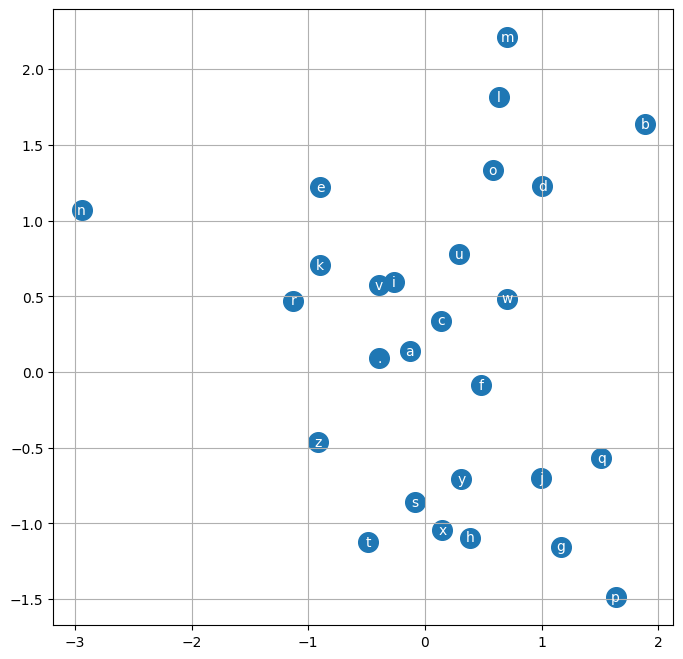

In [744]:
plt.figure(figsize=(8,8))
plt.scatter(c[:,0].data, c[:,1].data, s=200)
for i in range(c.shape[0]):
    plt.text(c[i,0].item(), c[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [745]:
g = torch.Generator().manual_seed(2147483647 + 100)

for _ in range(20):
    
    out = []
    context = [0] * block_size 
    while True:
      emb = c[torch.tensor([context])] 
      hpreact = emb.view(-1, n_embd * block_size) @ w1
      hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
      h = torch.tanh(hpreact)
      logits = h @ w2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

juliah.
perrey.
khyliah.
terra.
tayth.
bretie.
gric.
aaa.
kani.
ayden.
jorneyer.
taquan.
gedmarjon.
jamir.
halmereyna.
han.
trey.
amina.
wille.
son.
